# Análisis exploratorio

Antes de plantear el modelo quiero ver dos cosas en cada sistema (Península, Baleares y Canarias):

1. Qué forma tiene la relación entre la temperatura y la demanda.
2. A qué temperatura la demanda es mínima: será la **temperatura base** (T_base) a partir de la cual cuento los grados de frío y de calor.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent          # Jupyter arranca en notebooks/, así que subo un nivel
sys.path.append(str(RAIZ / "src"))

from config import FIGURAS
from features import cargar_sistema
from graficos import NOMBRES_SISTEMA
from poblacion import POBLACION

FIGURAS.mkdir(parents=True, exist_ok=True)

## 1. Una temperatura por sistema

Ni REData ni Open-Meteo dan una temperatura "de la Península" o "de Canarias", así que hay que construirla. Mi primera idea fue tomar 6–10 ciudades grandes que cubrieran los distintos climas (continental, mediterráneo, atlántico y sur), pero eso deja fuera media España y el peso de cada ciudad sería arbitrario.

Al final tomé **la capital de cada provincia** (47 en la Península, Palma, Ibiza y Mahón en Baleares, y las dos capitales canarias) y las ponderé por **población provincial** (INE, 1 de enero de 2023):

- peso de la provincia = población de la provincia / población total del sistema
- temperatura del sistema = Σ peso · temperatura de su capital

La idea es que la demanda la generan las personas, así que un grado más en Madrid debería pesar más que uno en Soria. El cálculo está en `cargar_sistema` (`src/features.py`).

In [7]:
# los pesos más grandes de cada sistema
for sistema, provincias in POBLACION.items():
    pesos = pd.Series(provincias) / sum(provincias.values())
    print(sistema, (pesos.sort_values(ascending=False).head(5) * 100).round(1).to_dict())

peninsular {'madrid': 15.4, 'barcelona': 13.1, 'valencia': 6.0, 'sevilla': 4.4, 'alicante': 4.4}
baleares {'palma': 77.7, 'ibiza': 14.1, 'mahon': 8.2}
canarias {'las_palmas': 51.8, 'santa_cruz_tenerife': 48.2}


In [8]:
datos = {sistema: cargar_sistema(sistema) for sistema in POBLACION}

for sistema, d in datos.items():
    print(f"{sistema}: {d.shape[0]} días, vacíos = {int(d.isna().sum().sum())}")

peninsular: 1826 días, vacíos = 0
baleares: 1826 días, vacíos = 0
canarias: 1826 días, vacíos = 0


## 2. Demanda frente a temperatura
Ahora quiero ver cuál es la forma de la nube de puntos (temperatura, demanda_mwh).

Un punto por día, separando laborables y fines de semana.

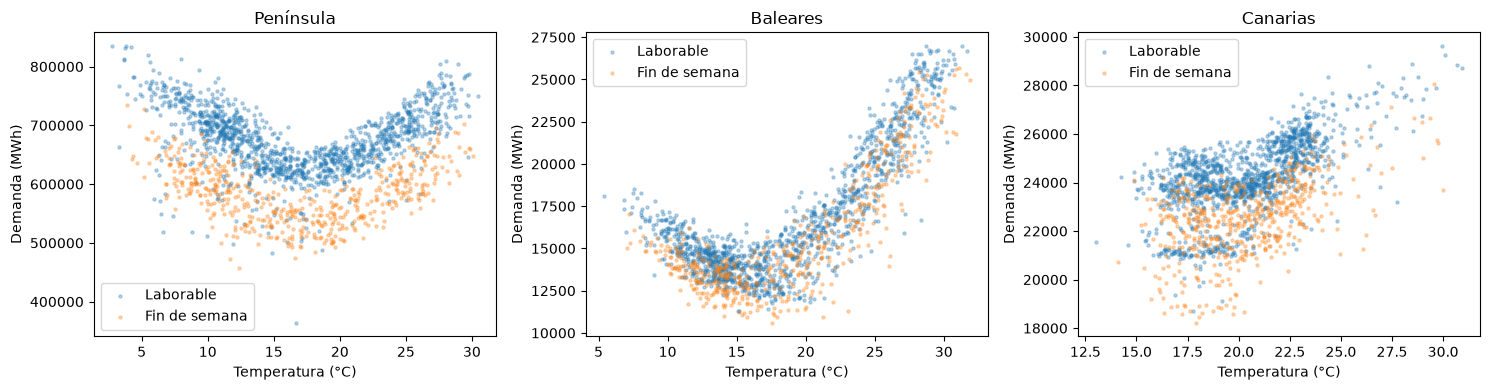

In [ ]:
df = pd.concat(datos, names=["sistema"]).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, sistema in zip(axes, datos):          
    grupo = df[df["sistema"] == sistema]
    laborable = grupo["fecha"].dt.day_of_week < 5   # lunes = 0 ... domingo = 6
    lab = grupo[laborable]
    finde = grupo[~laborable]

    ax.scatter(lab["temperatura"], lab["demanda_mwh"], s=5, alpha=0.3, label="Laborable")
    ax.scatter(finde["temperatura"], finde["demanda_mwh"], s=5, alpha=0.3, label="Fin de semana")

    ax.set_title(NOMBRES_SISTEMA[sistema])
    ax.set_xlabel("Temperatura (°C)")
    ax.set_ylabel("Demanda (MWh)")
    ax.legend()

plt.tight_layout()
fig.savefig(FIGURAS / "eda_dispersion.png", dpi=120, bbox_inches="tight")
plt.show()

**Qué se ve:**
- **Península**: una U clara, la demanda sube tanto con el frío como con el calor. Los fines de semana forman la misma U pero desplazada hacia abajo, unos 100 000 MWh: el día de la semana mueve el nivel y no la forma.

- **Baleares**: también es una U, pero la rama del calor tiene una mayor pendiente, no es simétrica. En verano coinciden el calor y el turismo, y en esta gráfica no se pueden separar.

- **Canarias**: casi solo hay rama de calor. Apenas hay días fríos, así que va a ser difícil medir el efecto del frío.

## 3. Temperatura base

Para leer el mínimo de la U agrupo los días en **tramos de 1 °C** (todos los días entre 16,5 y 17,5 °C van al tramo 17) y calculo la demanda media de cada tramo. Así la nube de puntos se convierte en una línea y el mínimo se lee directamente.

- Uso **solo laborables**: el fin de semana baja la demanda y mezclarlo ensucia el mínimo.
- Quito los tramos con menos de 15 días, que en los extremos dan medias poco fiables.

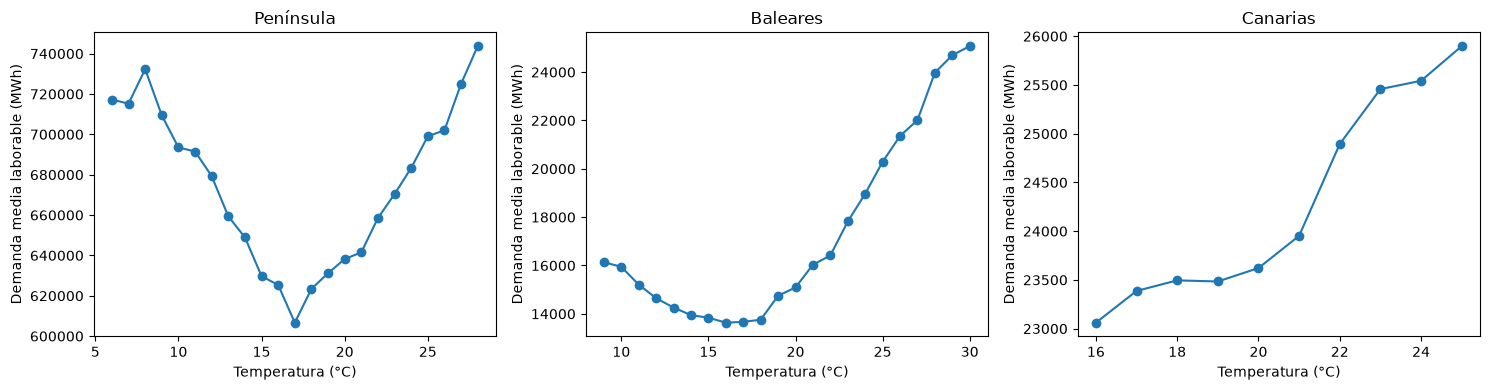

sistema
baleares      16.0
canarias      16.0
peninsular    17.0
Name: mean, dtype: float64


In [10]:
lab = df[df["fecha"].dt.day_of_week < 5].copy()
lab["tramo"] = lab["temperatura"].round()

tabla = lab.groupby(["sistema", "tramo"])["demanda_mwh"].agg(["mean", "size"])
tabla = tabla[tabla["size"] >= 15]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, sistema in zip(axes, datos):
    t = tabla.loc[sistema]
    ax.plot(t.index, t["mean"], marker="o")
    ax.set_title(NOMBRES_SISTEMA[sistema])
    ax.set_xlabel("Temperatura (°C)")
    ax.set_ylabel("Demanda media laborable (MWh)")

plt.tight_layout()
fig.savefig(FIGURAS / "eda_temperatura_base.png", dpi=120, bbox_inches="tight")
plt.show()

# tramo con la demanda mínima en cada sistema
print(tabla["mean"].groupby(level="sistema").idxmin().str[1])

**Qué se ve:**
- **Península**: mínimo muy marcado en **17 °C**.
- **Baleares**: el fondo es plano entre 15 y 18 °C, con el mínimo en **16 °C**.
- **Canarias**: el mínimo sale en 16 °C, pero es el primer tramo con datos: la curva solo sube. Uso **16 °C** igual que en Baleares, sabiendo que por debajo casi no hay días.

Con T_base parto la temperatura en dos variables, una para el frío y otra para el calor:

- HDD = max(T_base − T, 0): grados de frío por debajo de la base.
- CDD = max(T − T_base, 0): grados de calor por encima de la base.

| T del día (T_base = 17) | HDD | CDD |
|---|---|---|
| 10 °C | 7 | 0 |
| 17 °C | 0 | 0 |
| 25 °C | 0 | 8 |

Así el modelo puede estudiarse como dos pendientes lineales en vez de una relación cuadrática.

Voy a poder dibujar una V con una pendiente distinta a cada lado.

Además viendo los coeficientes que luego acompañarán a HDD y CDD podré deducir que cambio de temperatura influye más en la demanda enérgetica, el calor o el frío.

## 4. Evolución en el tiempo

Serie diaria con medias móviles de 30 y 365 días, para ver la estacionalidad y si el nivel cambia de un año a otro.

Esto me va a sugerir luego si necesito añadir algunas variables extra a mi modelo (año, agrupar semanas, separar laborables y festivos…).

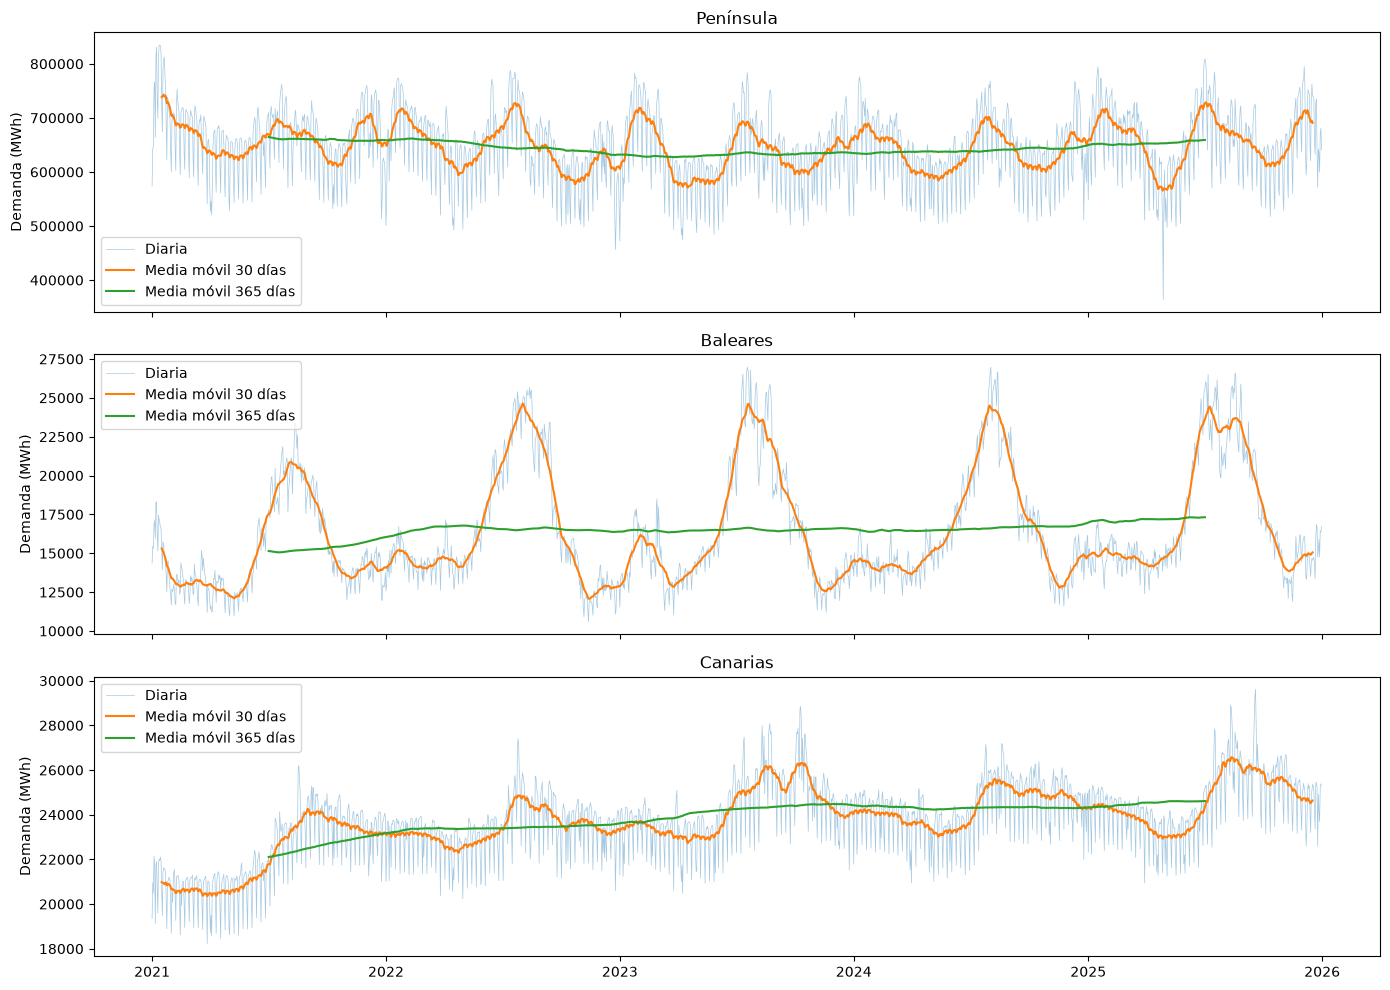

      peninsular  baleares  canarias
año                                 
2021    664509.0   15146.0   22108.0
2022    645208.0   16553.0   23387.0
2023    633910.0   16568.0   24254.0
2024    638328.0   16568.0   24307.0
2025    659184.0   17318.0   24613.0

      peninsular  baleares  canarias
año                                 
2021         NaN       NaN       NaN
2022        -2.9       9.3       5.8
2023        -1.8       0.1       3.7
2024         0.7       0.0       0.2
2025         3.3       4.5       1.3


In [15]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for ax, (sistema, d) in zip(axes, datos.items()):
    demanda = d["demanda_mwh"]
    ax.plot(demanda.index, demanda, linewidth=0.5, alpha=0.4, label="Diaria")
    ax.plot(demanda.index, demanda.rolling(30, center=True).mean(),  label="Media móvil 30 días")
    ax.plot(demanda.index, demanda.rolling(365, center=True).mean(),  label="Media móvil 365 días")
    ax.set_title(NOMBRES_SISTEMA[sistema])
    ax.set_ylabel("Demanda (MWh)")
    ax.legend()

plt.tight_layout()
fig.savefig(FIGURAS / "eda_series.png", dpi=120, bbox_inches="tight")
plt.show()

# demanda media por año y su variación respecto al año anterior
anual = pd.DataFrame({
    sistema: d["demanda_mwh"].groupby(d.index.year).mean()
    for sistema, d in datos.items()
})
anual.index.name = "año"
print(anual.round(0))
print()
print((anual.pct_change() * 100).round(1))

**Qué se ve:**
- La estacionalidad de cada sistema es distinta: la Península tiene dos picos (invierno y verano), Baleares un pico de verano enorme y Canarias una curva bastante plana con algo más de demanda a final de verano.
- **El nivel cambia de un año a otro** y no por la temperatura: la Península baja en 2022 y 2023 (crisis energética) y se recupera en 2025; Baleares sube un 9 % en 2022 y Canarias crece de 2021 a 2023, seguramente por la vuelta del turismo después del COVID. 
    - Esto pide una variable de año en el modelo.
    
- El pico hacia abajo de abril de 2025 en la Península es el **apagón del 28 de abril**.